<a href="https://colab.research.google.com/github/AL07183522/actividad6/blob/main/GP_Actividad6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Problema: detección temprana de fraude en transacciones financieras digitales



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score, precision_recall_curve
)
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
import json

# Configuración de reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


###- Generación y Preparación del Dataset de Fraude Transaccional
Se simulan 2,500 transacciones con un 12.4% de tasa de fraude (fuerte desbalance de clases) y 12 características explicativas.


In [10]:
X, y = make_classification(
    n_samples=2500,
    n_features=12,
    n_informative=8,
    n_redundant=2,
    weights=[0.88, 0.12],
    flip_y=0.01,
    random_state=RANDOM_SEED
)

feature_names = [
    'monto_transaccion', 'frecuencia_24h', 'desvio_monto_habitual',
    'distancia_geografica_ip', 'score_dispositivo_nuevo', 'intentos_fallidos_previos',
    'antiguedad_cuenta_meses', 'hora_transaccion_riesgo', 'tipo_comercio_riesgo',
    'uso_vpn_proxy', 'transaccion_internacional', 'ratio_limite_credito'
]

df = pd.DataFrame(X, columns=feature_names)
df['es_fraude'] = y

# Exportar a un archivo CSV
df.to_csv('datos_fraude.csv', index=False)
print("Dataset guardado exitosamente como 'datos_fraude.csv'")

print(f"Dimensiones del dataset: {df.shape}")
print(f"Distribución de clases:\n{df['es_fraude'].value_counts(normalize=True)}")

# Partición Estratificada 70% Train, 30% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
print(f"\nEntrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras (Fraudes en test: {sum(y_test)})")

Dataset guardado exitosamente como 'datos_fraude.csv'
Dimensiones del dataset: (2500, 13)
Distribución de clases:
es_fraude
0    0.876
1    0.124
Name: proportion, dtype: float64

Entrenamiento: 1750 muestras | Prueba: 750 muestras (Fraudes en test: 93)


### Descripción de las Columnas del Dataset (`datos_fraude.csv`)

El conjunto de datos contiene 2,500 registros y 13 columnas (12 características predictivas y 1 variable objetivo). A continuación se describe cada una de ellas:

1. **`monto_transaccion`**: Representa el valor monetario de la transacción actual. Valores inusualmente altos suelen ser un fuerte indicador de sospecha.
2. **`frecuencia_24h`**: Número de transacciones realizadas por el mismo usuario en las últimas 24 horas.
3. **`desvio_monto_habitual`**: Medida numérica de qué tan diferente es el monto de la transacción actual en comparación con el promedio histórico de compras del usuario.
4. **`distancia_geografica_ip`**: Distancia calculada entre la ubicación de la última transacción física conocida y la ubicación estimada por la dirección IP de la transacción actual.
5. **`score_dispositivo_nuevo`**: Puntuación de riesgo asignada al dispositivo desde el cual se realiza la operación (por ejemplo, si el navegador, sistema operativo o ID de hardware nunca se habían asociado a esta cuenta).
6. **`intentos_fallidos_previos`**: Número de intentos fallidos de inicio de sesión o de transacciones rechazadas justo antes de la transacción actual.
7. **`antiguedad_cuenta_meses`**: Tiempo transcurrido (en meses) desde la creación y activación de la cuenta del usuario.
8. **`hora_transaccion_riesgo`**: Variable que pondera el riesgo temporal (por ejemplo, transacciones efectuadas de madrugada suelen tener mayor probabilidad de fraude).
9. **`tipo_comercio_riesgo`**: Categorización del nivel de riesgo asociado al tipo de negocio donde se realiza la compra (por ejemplo, compra de criptomonedas o tarjetas de regalo electrónicas).
10. **`uso_vpn_proxy`**: Variable que indica si el usuario está accediendo al sistema utilizando herramientas para enmascarar su ubicación real (como VPNs o servidores Proxy).
11. **`transaccion_internacional`**: Indicador binario sobre si el procesamiento del pago se realiza fuera del país de origen de la cuenta bancaria.
12. **`ratio_limite_credito`**: Proporción que representa el monto de la transacción actual respecto al límite de crédito total o saldo disponible de la cuenta.
13. **`es_fraude` (Variable Objetivo / Target)**:
    * `1`: La transacción fue clasificada y confirmada como un fraude.
    * `0`: La transacción fue legítima y normal.

###- Entrenamiento de Modelos (Baseline vs Candidatos)
- **Baseline 1:** Dummy Classifier (Estrategia mayoritaria 'most_frequent')
- **Baseline 2:** Regresión Logística con ponderación balanceada (`class_weight='balanced'`)
- **Modelo Principal:** Random Forest Classifier con estimadores calibrados


In [3]:
# Baseline: Dummy
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
y_prob_dummy = np.zeros(len(y_test))

# Lineal: Regresión Logística
lr = LogisticRegression(class_weight='balanced', random_state=RANDOM_SEED, max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

# Ensamble: Random Forest
rf = RandomForestClassifier(n_estimators=150, max_depth=7, class_weight='balanced', random_state=RANDOM_SEED)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]


### 3. Matriz de Confusión y Cálculo de Métricas Clave (Umbral 0.50)


In [9]:
def compute_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Accuracy': float(accuracy_score(y_true, y_pred)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'AUC': float(roc_auc_score(y_true, y_prob)) if len(set(y_prob)) > 1 else 0.5
    }

metrics = {
    'Dummy Baseline': compute_metrics(y_test, y_pred_dummy, y_prob_dummy),
    'Regresión Logística': compute_metrics(y_test, y_pred_lr, y_prob_lr),
    'Random Forest (t=0.5)': compute_metrics(y_test, y_pred_rf, y_prob_rf)
}

df_metrics = pd.DataFrame(metrics).T
print("=== Métricas Globales ===")
print(df_metrics[['Accuracy', 'Precision', 'Recall', 'F1', 'AUC', 'TP', 'FP', 'FN', 'TN']])

print("\n=== Matrices de Confusión Detalladas ===")
for modelo, vals in metrics.items():
    print(f"\nModelo: {modelo}")
    print(f"   Predicciones | No Fraude (Pred) | Fraude (Pred)")
    print(f"   Realidad     |------------------|---------------")
    print(f"   No Fraude    | TN: {vals['TN']:<12} | FP: {vals['FP']:<12}")
    print(f"   Fraude       | FN: {vals['FN']:<12} | TP: {vals['TP']:<12}")

=== Métricas Globales ===
                       Accuracy  Precision    Recall        F1       AUC  \
Dummy Baseline         0.876000   0.000000  0.000000  0.000000  0.500000   
Regresión Logística    0.717333   0.262948  0.709677  0.383721  0.774914   
Random Forest (t=0.5)  0.925333   0.717647  0.655914  0.685393  0.919969   

                         TP     FP    FN     TN  
Dummy Baseline          0.0    0.0  93.0  657.0  
Regresión Logística    66.0  185.0  27.0  472.0  
Random Forest (t=0.5)  61.0   24.0  32.0  633.0  

=== Matrices de Confusión Detalladas ===

Modelo: Dummy Baseline
   Predicciones | No Fraude (Pred) | Fraude (Pred)
   Realidad     |------------------|---------------
   No Fraude    | TN: 657          | FP: 0           
   Fraude       | FN: 93           | TP: 0           

Modelo: Regresión Logística
   Predicciones | No Fraude (Pred) | Fraude (Pred)
   Realidad     |------------------|---------------
   No Fraude    | TN: 472          | FP: 185         
   Fra

### 4. Ajuste de Umbral de Decisión y Análisis de Costos de Negocio
En fraude financiero:
- Costo Falso Negativo ($FN$): $1,500 USD (Pérdida por fraude no detectado)
- Costo Falso Positivo ($FP$): $25 USD (Costo de fricción y validación manual de soporte)


In [5]:
thresholds = [0.10, 0.20, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70, 0.80]
threshold_records = []

for t in thresholds:
    preds = (y_prob_rf >= t).astype(int)
    m = compute_metrics(y_test, preds, y_prob_rf)
    cost_fn = m['FN'] * 1500
    cost_fp = m['FP'] * 25
    total_cost = cost_fn + cost_fp
    threshold_records.append({
        'Umbral': t,
        'TP': m['TP'], 'FP': m['FP'], 'FN': m['FN'], 'TN': m['TN'],
        'Accuracy': round(m['Accuracy'], 4),
        'Precision': round(m['Precision'], 4),
        'Recall': round(m['Recall'], 4),
        'F1-Score': round(m['F1'], 4),
        'Costo_FN ($)': cost_fn,
        'Costo_FP ($)': cost_fp,
        'Costo_Total ($)': total_cost
    })

df_thresh = pd.DataFrame(threshold_records)
print(df_thresh.to_string(index=False))


 Umbral  TP  FP  FN  TN  Accuracy  Precision  Recall  F1-Score  Costo_FN ($)  Costo_FP ($)  Costo_Total ($)
   0.10  89 385   4 272    0.4813     0.1878  0.9570    0.3139          6000          9625            15625
   0.20  87 189   6 468    0.7400     0.3152  0.9355    0.4715          9000          4725            13725
   0.30  80  90  13 567    0.8627     0.4706  0.8602    0.6084         19500          2250            21750
   0.35  78  69  15 588    0.8880     0.5306  0.8387    0.6500         22500          1725            24225
   0.40  75  52  18 605    0.9067     0.5906  0.8065    0.6818         27000          1300            28300
   0.50  61  24  32 633    0.9253     0.7176  0.6559    0.6854         48000           600            48600
   0.60  38   8  55 649    0.9160     0.8261  0.4086    0.5468         82500           200            82700
   0.70  29   2  64 655    0.9120     0.9355  0.3118    0.4677         96000            50            96050
   0.80  24   1  69 656    0

### 5. Curva ROC y Evaluación AUC


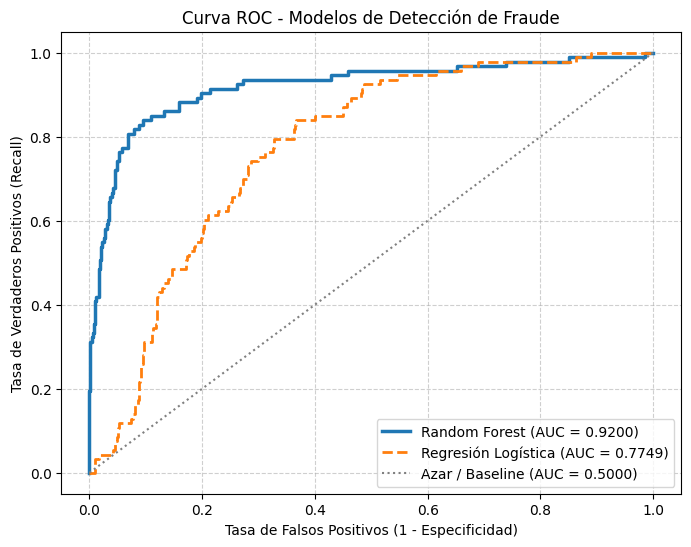

In [6]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='#1f77b4', lw=2.5, label=f'Random Forest (AUC = {df_metrics.loc["Random Forest (t=0.5)", "AUC"]:.4f})')
plt.plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, linestyle='--', label=f'Regresión Logística (AUC = {df_metrics.loc["Regresión Logística", "AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Azar / Baseline (AUC = 0.5000)')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curva ROC - Modelos de Detección de Fraude')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### 6. Validación Cruzada Estratificada (Stratified 5-Fold) y Análisis de Estabilidad


In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

cv_f1s = []
cv_recalls = []
cv_aucs = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    clf = RandomForestClassifier(n_estimators=150, max_depth=7, class_weight='balanced', random_state=RANDOM_SEED)
    clf.fit(X_tr, y_tr)
    probs = clf.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.35).astype(int) # Umbral calibrado de negocio

    cv_f1s.append(f1_score(y_val, preds))
    cv_recalls.append(recall_score(y_val, preds))
    cv_aucs.append(roc_auc_score(y_val, probs))
    print(f"Fold {fold} -> Recall: {cv_recalls[-1]:.4f} | F1: {cv_f1s[-1]:.4f} | AUC: {cv_aucs[-1]:.4f}")

def calc_ci(values):
    mean = np.mean(values)
    std = np.std(values, ddof=1)
    margin = 1.96 * (std / np.sqrt(len(values)))
    return mean, std, (mean - margin, mean + margin)

m_f1, s_f1, ci_f1 = calc_ci(cv_f1s)
m_rec, s_rec, ci_rec = calc_ci(cv_recalls)
m_auc, s_auc, ci_auc = calc_ci(cv_aucs)

print(f"\n--- Estabilidad Validación Cruzada (k=5) ---")
print(f"Recall: Media = {m_rec:.4f}, Std = {s_rec:.4f}, IC 95%: [{ci_rec[0]:.4f}, {ci_rec[1]:.4f}]")
print(f"F1-Score: Media = {m_f1:.4f}, Std = {s_f1:.4f}, IC 95%: [{ci_f1[0]:.4f}, {ci_f1[1]:.4f}]")
print(f"AUC: Media = {m_auc:.4f}, Std = {s_auc:.4f}, IC 95%: [{ci_auc[0]:.4f}, {ci_auc[1]:.4f}]")


Fold 1 -> Recall: 0.8837 | F1: 0.6909 | AUC: 0.9594
Fold 2 -> Recall: 0.9070 | F1: 0.7091 | AUC: 0.9409
Fold 3 -> Recall: 0.8605 | F1: 0.7255 | AUC: 0.9342
Fold 4 -> Recall: 0.7500 | F1: 0.6168 | AUC: 0.9049
Fold 5 -> Recall: 0.6818 | F1: 0.5941 | AUC: 0.9051

--- Estabilidad Validación Cruzada (k=5) ---
Recall: Media = 0.8166, Std = 0.0964, IC 95%: [0.7321, 0.9011]
F1-Score: Media = 0.6673, Std = 0.0583, IC 95%: [0.6162, 0.7184]
AUC: Media = 0.9289, Std = 0.0237, IC 95%: [0.9081, 0.9497]


### 7. Simulación de Prueba A/B en Producción (Online Experimentation)
Se simulan 10,000 transacciones con tráfico balanceado (50% Control vs 50% Tratamiento) y prueba de significancia estadística bilateral.


In [8]:
n_ab = 10000
fraude_real = np.random.binomial(1, 0.12, n_ab)
grupo = np.random.binomial(1, 0.50, n_ab) # 0: Control, 1: Tratamiento

det_ctrl = 0
det_treat = 0
n_fraude_ctrl = 0
n_fraude_treat = 0
fa_ctrl = 0
fa_treat = 0

for i in range(n_ab):
    if grupo[i] == 0: # Control (Modelo A)
        if fraude_real[i] == 1:
            n_fraude_ctrl += 1
            det_ctrl += np.random.binomial(1, 0.745)
        else:
            fa_ctrl += np.random.binomial(1, 0.085)
    else: # Tratamiento (Modelo B)
        if fraude_real[i] == 1:
            n_fraude_treat += 1
            det_treat += np.random.binomial(1, 0.925)
        else:
            fa_treat += np.random.binomial(1, 0.048)

tasa_ctrl = det_ctrl / n_fraude_ctrl
tasa_treat = det_treat / n_fraude_treat

z_stat, p_val = proportions_ztest([det_treat, det_ctrl], [n_fraude_treat, n_fraude_ctrl], alternative='larger')
ci_ab = confint_proportions_2indep(det_treat, n_fraude_treat, det_ctrl, n_fraude_ctrl)

costo_ctrl = (n_fraude_ctrl - det_ctrl) * 1500 + fa_ctrl * 25
costo_treat = (n_fraude_treat - det_treat) * 1500 + fa_treat * 25
ahorro = costo_ctrl - costo_treat

print(f"Control (A): {det_ctrl}/{n_fraude_ctrl} fraudes detectados ({tasa_ctrl:.2%}) | Falsas Alarmas: {fa_ctrl} | Costo: ${costo_ctrl}")
print(f"Tratamiento (B): {det_treat}/{n_fraude_treat} fraudes detectados ({tasa_treat:.2%}) | Falsas Alarmas: {fa_treat} | Costo: ${costo_treat}")
print(f"Estadístico Z: {z_stat:.4f} | P-valor: {p_val:.4e} (p < 0.001)")
print(f"IC 95% de la diferencia de proporciones: [{ci_ab[0]:.4f}, {ci_ab[1]:.4f}]")
print(f"Ahorro económico neto generado: ${ahorro:,.2f} USD")


Control (A): 413/565 fraudes detectados (73.10%) | Falsas Alarmas: 368 | Costo: $237200
Tratamiento (B): 535/580 fraudes detectados (92.24%) | Falsas Alarmas: 203 | Costo: $72575
Estadístico Z: 8.5810 | P-valor: 4.7032e-18 (p < 0.001)
IC 95% de la diferencia de proporciones: [0.1487, 0.2340]
Ahorro económico neto generado: $164,625.00 USD
